In [1]:
# U.S. Department of State notice, last updated August 28, 2026.
# https://travel.state.gov/content/travel/en/News/visas-news/immigrant-visa-processing-updates-for-nationalities-at-high-risk-of-public-benefits-usage.html
#
# Effective January 21, 2026, the Department paused immigrant visa issuance
# for nationals of these 75 countries. The same notice says that pause is
# no longer in effect as of August 21, 2026.
# Names below are the names used in the notice. Values are ISO country codes
# used to match map boundaries. Burma is Myanmar, Cape Verde is Cabo Verde,
# and the Kyrgyz Republic is Kyrgyzstan.

countries = {
    "Afghanistan": "AFG",
    "Albania": "ALB",
    "Algeria": "DZA",
    "Antigua and Barbuda": "ATG",
    "Armenia": "ARM",
    "Azerbaijan": "AZE",
    "Bahamas": "BHS",
    "Bangladesh": "BGD",
    "Barbados": "BRB",
    "Belarus": "BLR",
    "Belize": "BLZ",
    "Bhutan": "BTN",
    "Bosnia and Herzegovina": "BIH",
    "Brazil": "BRA",
    "Burma": "MMR",
    "Cambodia": "KHM",
    "Cameroon": "CMR",
    "Cape Verde": "CPV",
    "Colombia": "COL",
    "Cote d'Ivoire": "CIV",
    "Cuba": "CUB",
    "Democratic Republic of the Congo": "COD",
    "Dominica": "DMA",
    "Egypt": "EGY",
    "Eritrea": "ERI",
    "Ethiopia": "ETH",
    "Fiji": "FJI",
    "The Gambia": "GMB",
    "Georgia": "GEO",
    "Ghana": "GHA",
    "Grenada": "GRD",
    "Guatemala": "GTM",
    "Guinea": "GIN",
    "Haiti": "HTI",
    "Iran": "IRN",
    "Iraq": "IRQ",
    "Jamaica": "JAM",
    "Jordan": "JOR",
    "Kazakhstan": "KAZ",
    "Kosovo": "KOS",
    "Kuwait": "KWT",
    "Kyrgyz Republic": "KGZ",
    "Laos": "LAO",
    "Lebanon": "LBN",
    "Liberia": "LBR",
    "Libya": "LBY",
    "Moldova": "MDA",
    "Mongolia": "MNG",
    "Montenegro": "MNE",
    "Morocco": "MAR",
    "Nepal": "NPL",
    "Nicaragua": "NIC",
    "Nigeria": "NGA",
    "North Macedonia": "MKD",
    "Pakistan": "PAK",
    "Republic of the Congo": "COG",
    "Russia": "RUS",
    "Rwanda": "RWA",
    "Saint Kitts and Nevis": "KNA",
    "Saint Lucia": "LCA",
    "Saint Vincent and the Grenadines": "VCT",
    "Senegal": "SEN",
    "Sierra Leone": "SLE",
    "Somalia": "SOM",
    "South Sudan": "SSD",
    "Sudan": "SDN",
    "Syria": "SYR",
    "Tanzania": "TZA",
    "Thailand": "THA",
    "Togo": "TGO",
    "Tunisia": "TUN",
    "Uganda": "UGA",
    "Uruguay": "URY",
    "Uzbekistan": "UZB",
    "Yemen": "YEM",
}

len(countries)


75

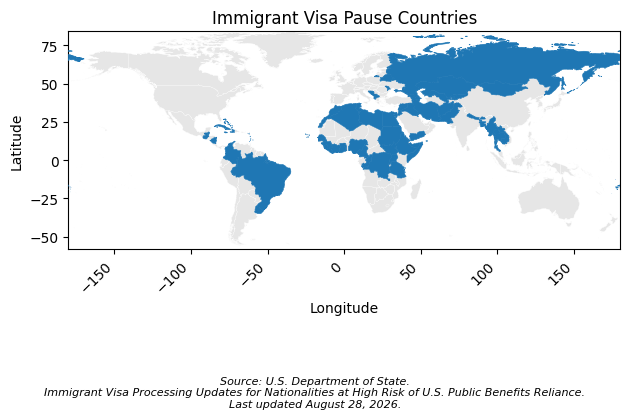

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import requests
from matplotlib.collections import PolyCollection

# Natural Earth 1:50m includes the small island countries in the notice.
# https://www.naturalearthdata.com/
cache_path = Path("cache") / "ne_50m_admin_0_countries.geojson"
if not cache_path.exists():
    cache_path.parent.mkdir(exist_ok=True)
    url = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_50m_admin_0_countries.geojson"
    response = requests.get(url, timeout=120)
    response.raise_for_status()
    cache_path.write_bytes(response.content)

def feature_code(props):
    iso = props.get("ISO_A3")
    if iso and iso != "-99":
        return iso
    return props.get("ADM0_A3")

def exteriors(geometry):
    kind = geometry["type"]
    coords = geometry["coordinates"]
    if kind == "Polygon":
        polygons = [coords]
    elif kind == "MultiPolygon":
        polygons = coords
    else:
        polygons = []
    for polygon in polygons:
        if not polygon:
            continue
        current = []
        prev_lon = None
        for point in polygon[0]:
            lon, lat = point[0], point[1]
            if prev_lon is not None and abs(lon - prev_lon) > 180 and len(current) >= 3:
                yield current
                current = []
            current.append((lon, lat))
            prev_lon = lon
        if len(current) >= 3:
            yield current

world = json.loads(cache_path.read_text(encoding="utf-8"))
wanted = set(countries.values())
found = set()
other = []
highlight = []
for feature in world["features"]:
    code = feature_code(feature["properties"])
    if code == "ATA":
        continue
    rings = list(exteriors(feature["geometry"]))
    # Natural Earth draws Somaliland separately. The notice names Somalia.
    if code in wanted or (code == "SOL" and "SOM" in wanted):
        highlight.extend(rings)
        if code in wanted:
            found.add(code)
    else:
        other.extend(rings)

missing = sorted(name for name, code in countries.items() if code not in found)
if missing:
    raise ValueError(missing)

fig, ax = plt.subplots()
ax.add_collection(PolyCollection(other, facecolor="#e6e6e6", edgecolor="white", linewidths=0.2))
ax.add_collection(PolyCollection(highlight, facecolor="C0", edgecolor="C0", linewidths=0.4, zorder=3))
ax.set_xlim(-180, 180)
ax.set_ylim(-58, 84)
ax.set_aspect("equal", adjustable="box")
ax.set_title("Immigrant Visa Pause Countries")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.xticks(rotation=45, ha="right")
plt.subplots_adjust(bottom=0.3)
plt.figtext(
    0.5, -0.03,
    "Source: U.S. Department of State.\n"
    "Immigrant Visa Processing Updates for Nationalities at High Risk of U.S. Public Benefits Reliance.\n"
    "Last updated August 28, 2026.",
    ha="center",
    fontsize=8,
    style="italic",
)
plt.tight_layout()
plt.show()
